# Анализ рынка общепита города Москвы

- Автор: Морозов Сергей Валентинович
 

### Цели и задачи проекта

_**Цель:**  
Провести исследовательский анализ рынка общепита Москвы по заказу фонда "Shut Up and Take My Money"._  
_**Задачи:**_  
1. Загрузить данные и познакомиться с их содержимым.
2. Провести предобработку данных.
3. Провести исследовательский анализ данных:
- Определить категории заведений представленых в исходных датасетах, а именно: количество объектов общественного питания по каждой категории, результат сопроводить подходящей визуализацией.
- Какие административные районы Москвы присутствуют в данных? Исследовать распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы. Результат сопроводите подходящими визуализациями.
- Изучить соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения. Каких заведений больше — сетевых или несетевых? 
Какие категории заведений чаще являются сетевыми? Исследовать данные и построить необходимые визуализации.
- Исследовать количество посадочных мест в заведениях. Встречаются ли в данных аномальные значения или выбросы? Если да, то с чем они могут быть связаны? 
Привести для каждой категории заведений наиболее типичное для него количество посадочных мест. Результат сопроводить подходящими визуализациями.
- Исследовать рейтинг заведений. Визуализировать распределение средних рейтингов по категориям заведений. Сильно ли различаются усреднённые рейтинги для разных типов общепита?
- Изучить, с какими данными показывают самую сильную корреляцию рейтинги заведений? Построить и визуализировать матрицу корреляции рейтинга заведения с разными данными: 
	его категория, 
	положение (административный район Москвы), 
	статус сетевого заведения, 
	количество мест, 
	ценовая категория и признак, 
	является ли заведения круглосуточным. Выберать самую сильную связь и проверьте её.
- Сгруппировать данные по названиям заведений и найти топ-15 популярных сетей в Москве. 
Для них посчитайть значения среднего рейтинга. Под популярностью понимается количество заведений этой сети в регионе. К какой категории заведений они относятся? Результат сопроводить подходящими визуализациями.
- Изучить вариацию среднего чека заведения (столбец middle_avg_bill) в зависимости от района Москвы. Проанализировать цены в центральном административном округе и других. 
Как удалённость от центра влияет на цены в заведениях? Результат сопроводить подходящими визуализациями.

4. Сформулировать итоговый вывод и рекомендации

### Описание данных
Для анализа поступили данные, составленные на основе данных сервисов Яндекс Карты и Яндекс Бизнес за лето 2022 года. Данные состоят из двух датасетов:

- `rest_info.csv` — информация об использовании клиентом услуг банка;
- `rest_price.csv` —  персональная информация клиентов.

Файл `rest_info.csv` содержит информацию о заведениях общественного питания:  
- name — название заведения;
- address — адрес заведения;
- district — административный район, в котором находится заведение, например Центральный административный округ;
- category — категория заведения, например «кафе», «пиццерия» или «кофейня»;
- hours — информация о днях и часах работы;
- rating — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);
- chain — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки):
0 — заведение не является сетевым;
1 — заведение является сетевым.
- seats — количество посадочных мест.

Файл `rest_price.csv` содержит информацию о среднем чеке в заведениях общественного питания:  
- price — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
- avg_bill — хранит среднюю стоимость заказа в виде диапазона, например:
«Средний счёт: 1000–1500 ₽»;
«Цена чашки капучино: 130–220 ₽»;
«Цена бокала пива: 400–600 ₽».
и так далее;
- middle_avg_bill — число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт»:  
Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.  
Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.  
Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.  
- middle_coffee_cup — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Цена одной чашки капучино»:  
Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.  
Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.  
Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.

### Содержимое проекта

1. Загрузка данных и знакомство с ними.
2. Предобработка данных.
3. Исследовательский анализ данных.
4. Итоговые выводы.

## 1. Загрузка данных и знакомство с ними

In [1]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем библиотеку для расчёта коэффициента корреляции phi_k
from phik import phik_matrix

In [2]:
# Выгружаем данные в переменные bank_df и clients_df
rest_info_df = pd.read_csv('https://code.s3.yandex.net/datasets/rest_info.csv')
rest_price_df = pd.read_csv('https://code.s3.yandex.net/datasets/rest_price.csv')

**_Знакомство с данными_**

In [3]:
rest_info_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


In [4]:
rest_price_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


In [5]:
rest_info_df.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [6]:
rest_price_df.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


**_Промежуточный вывод_**
- _Датасет `rest_info_df` имеет 8406 строк, столбцы hours, seats содержат пустые значения, остальные не имеют пропусков. Имеет смысл преобразовать тип данных столбцов rating, chain, seats к типу int8. Названия столбцов соответствуют стилю snake case и не требуют изменений. В стобце seats порядка 43% процентов прпуска, а в hours порядка 6.3%._
- _Датасет `rest_price_df` имеет 4058 строк, только столбец id, являющийся ключом имеет 4058 строк. Остальные содержат пропуски. Названия столбцов соответствуют стилю snake case и не требуют изменений. Преобразование типов данных в данном датасете не требуется_


### Подготовка единого датафрейма


In [7]:
# Чтобы не потерять данные, присоединим к бОльшему (по количеству строк) датафрейму меньший слева
print(f'Размер основного датафрема до объединения {rest_info_df.shape}')
df = rest_info_df.merge(rest_price_df, how='left')
print(f'Размер объединенного датафрема {df.shape}')

Размер основного датафрема до объединения (8406, 9)
Размер объединенного датафрема (8406, 13)


## 2. Предобработка данных


In [8]:
#Проверим типы данных в df
df.dtypes

id                    object
name                  object
category              object
address               object
district              object
hours                 object
rating               float64
chain                  int64
seats                float64
price                 object
avg_bill              object
middle_avg_bill      float64
middle_coffee_cup    float64
dtype: object

_Пожалуй, только поле seats требует преобразования в тип int8. Однако оно содержит пропуски, которые надо заполнить, чтобы преобразовать. Исследуем подробнее_  

In [9]:
df['seats'].describe()

count    4795.000000
mean      108.421689
std       122.833396
min         0.000000
25%        40.000000
50%        75.000000
75%       140.000000
max      1288.000000
Name: seats, dtype: float64

_Заполнение медианой или средним значением, на мой взгляд, исказит данные. Оставим данное поле как есть_

_**Анализ пропусков**_  
_Проанализируем наличие пропусков в дата фреймах. Для этого напишем функцию, которая отображает только те столбцы датафрейма, в которых есть пропуски_

In [10]:
def get_missing_field(df):
    #print(f'Пропущенные значения в датафрейме {df}')
    miss_dict = pd.DataFrame({
    'missing_count': df.isna().sum(),                 # абсолютное количество
    'missing_percent': (df.isna().mean() * 100).round(2)  # процент, округлённый до 2 знаков
    })
    return miss_dict[miss_dict['missing_count']>0]

In [11]:
# Анализ пропусков в датафреме rest_info_df
get_missing_field(rest_info_df)

,missing_count,missing_percent
hours,536,6.38
seats,3611,42.96


In [12]:
# Анализ пропусков в датафреме rest_price_df
get_missing_field(rest_price_df)

,missing_count,missing_percent
price,743,18.31
avg_bill,242,5.96
middle_avg_bill,909,22.40
middle_coffee_cup,3523,86.82


_Промежуточный вывод по пропускам: оставим пропуски как есть, можно будет вернуться к ним после дальнейшего анализа данных, при выявлении в них некорректных или аномальных данных, например отрицательных значений и т.п._

_Проверка данных на явные и неявные дубликаты._

In [13]:
# Проверим уникальность в столбцах 'name', 'category', 'address', 'district'
cols_to_check = ['name', 'category', 'address', 'district']
for col in cols_to_check:
    print(f"\n--- {col} ---")
    vc = df[col].value_counts(dropna=False)          
    print(vc.sort_index().head(30))                               
    print("Всего уникальных:", vc.nunique())


--- name ---
name
#КешбэкКафе                    1
+39 Pizzeria Mozzarella bar    1
1 Этаж                         1
1-я Креветочная                1
10 Идеальных Пицц              3
1001 Ночь                      1
100ловая                       1
100лоффка                      1
13                             1
13 Chef doner                  1
15 Kitchen+Bar                 1
15-й Шар                       1
16 Июня                        1
16 Тонн                        1
18 Грамм                       3
1901 Comfort Food Zone         1
1у                             1
2 Типа                         1
2-й Этаж                       1
2046                           1
21 Век                         1
22 Акра Кофе&Хлеб              1
2U-Ту-Ю                        1
3 Ступени                      1
351 Bar                        1
4 Сезона                       1
4.2. Bar                       1
4/1 Restaurant                 1
42 Coffee Shop                 1
47                      

_При визуальном анализе в проверяемых колонках неявные дубликаты не обнаружены, также можно сделать вывод, что нормализация по данным полям не требуется_

In [14]:
# Посмотрим на явные дубликаты
dup_exact = df.duplicated().sum()
print(f"\nЯвные дубликаты (полные совпадения строк): {dup_exact}")


Явные дубликаты (полные совпадения строк): 0


_Явных дубликатов нет_

In [15]:
# Посмотрим на неявные дубликаты по ключу id
key = 'id'
dup_by_key = df.duplicated(subset=key, keep=False).sum()
print(f"Строк с повторами по ключу '{key}': {dup_by_key}")

Строк с повторами по ключу 'id': 0


In [16]:
# Проверим дубликат по паре name и адрес согласно замечанию ревьюера
key = ['name', 'address']
dup_by_key = df.duplicated(subset=key, keep=False).sum()
print(f"Строк с повторами по ключу '{key}': {dup_by_key}")

Строк с повторами по ключу '['name', 'address']': 0


_Неяных дубликатов по паре "Название" и "Адрес" не выявлено.
Никаких преобразований данных в части дубликатов не требуется_

- _Для дальнейшей работы создаем новое поле `is_24_7` с обозначением того, что заведение работает ежедневно и круглосуточно, то есть 24/7:_
  - логическое значение `True` — если заведение работает ежедневно и круглосуточно;
  - логическое значение `False` — в противоположном случае.

_Создаем новое поле is_24_7_

In [17]:
# Создаём новое логическое поле is_24_7
# Предполагаем, что в колонке 'hours' нужное значение точно совпадает с фразой «ежедневно, круглосуточно»
df['is_24_7'] = df['hours'] == 'ежедневно, круглосуточно'

# Проверка: посмотрим уникальные значения в hours и долю 24/7 заведений
grouped = df.groupby('hours').size().reset_index(name='count')
sorted_grouped = grouped.sort_values(by='count', ascending=False)
print(sorted_grouped)

print(f"\nДоля круглосуточных заведений: {df['is_24_7'].mean():.2%}")

                                     hours  count
168                 ежедневно, 10:00–22:00    759
275               ежедневно, круглосуточно    730
213                 ежедневно, 11:00–23:00    396
175                 ежедневно, 10:00–23:00    310
229                 ежедневно, 12:00–00:00    254
...                                    ...    ...
566   пн-пт 08:30–20:30; сб,вс 10:00–21:00      1
567                      пн-пт 08:30–21:00      1
569   пн-пт 08:30–21:00; сб,вс 09:00–22:00      1
570   пн-пт 08:30–21:00; сб,вс 09:30–21:00      1
1306                     чт-вс 20:00–06:00      1

[1307 rows x 2 columns]

Доля круглосуточных заведений: 8.68%


In [18]:
df.shape

(8406, 14)

_Поле `'is_24_7'` создано, объединенный датафрейм увеличился на одну колонку_

### Промежуточный вывод
_Предобработка завершена. Предоставленные данные хорошего качества и не требовали много действий по предобработке._ 

В результате предобработки данных были выполнены следующие действия:
- Два исходных датасета объединены в один датафрейм;
- Проанализированы названия столбцов: они в стиле snake case;
- Изучены пропуски в данных. Пропуски есть, но не удалось явно выделить причину пропусков, а также не возникло понимания чем их заполнять, чтобы не исказить статистику. Поэтому их оставили как есть.
- Данные проверили на явные и неявные дубликаты — в данных их нет.

## 3. Исследовательский анализ данных


---

### Задача 1

Какие категории заведений представлены в данных? Исследуйте количество объектов общественного питания по каждой категории. Результат сопроводите подходящей визуализацией.

_В исходных данных можно выделить две категории: "category" и "district"_

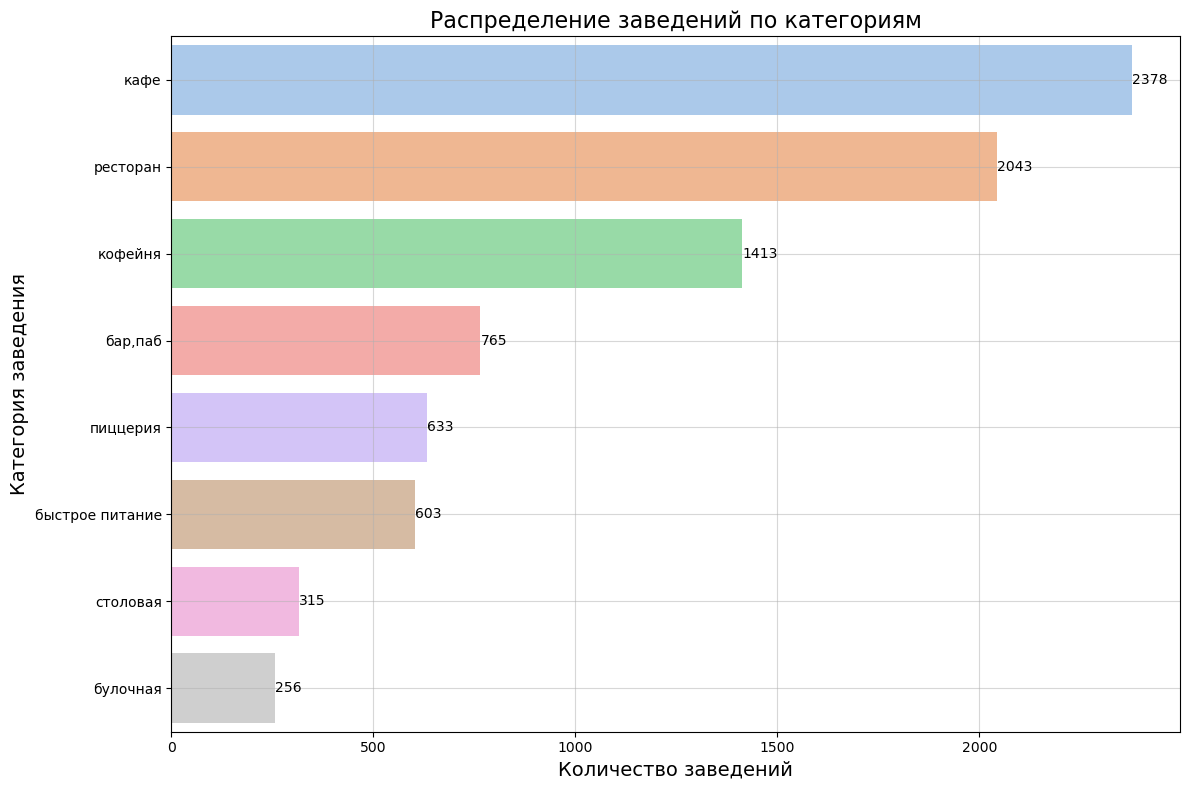


Доля каждой категории в процентах:
category
кафе               28.29
ресторан           24.30
кофейня            16.81
бар,паб             9.10
пиццерия            7.53
быстрое питание     7.17
столовая            3.75
булочная            3.05
Name: count, dtype: float64

Основные выводы:
Всего категорий: 8
Самая популярная категория: кафе (всего 2378 заведений)
Самая редкая категория: булочная (всего 256 заведений)


In [19]:
# Анализ категорий заведений(category)
category_counts = df['category'].value_counts()

# Визуализация
plt.figure(figsize=(12, 8))
ax = sns.barplot(x=category_counts.values, y=category_counts.index, hue=category_counts.index, palette='pastel', legend=False)

plt.title('Распределение заведений по категориям', fontsize=16)
plt.xlabel('Количество заведений', fontsize=14)
plt.ylabel('Категория заведения', fontsize=14)
plt.grid(True, alpha=0.5)
plt.tight_layout()
# Указываем реальные значения на самом графике
for container in ax.containers:
    ax.bar_label(container)

# Показываем график
plt.show()

# Доля каждой категории в процентах
category_pct = (category_counts / category_counts.sum()) * 100
print("\nДоля каждой категории в процентах:")
print(category_pct.round(2))

# Дополнительные выводы
print("\nОсновные выводы:")
print(f"Всего категорий: {len(category_counts)}")
print(f"Самая популярная категория: {category_counts.idxmax()} (всего {category_counts.max()} заведений)")
print(f"Самая редкая категория: {category_counts.idxmin()} (всего {category_counts.min()} заведений)")

_Выводы:_
- Всего категорий: 8
- Самая популярная категория: кафе (всего 2378 заведений)
- Самая редкая категория: булочная (всего 256 заведений)  
_Результаты анализа:_
Основные категории заведений:
- Кафе
- Кофейни
- Пиццерии
- Быстрое питание
- Рестораны
- Булочные
- Бары и пабы
- Столовые

Процентное соотношение:
Кафе — около 30% от всех заведений
Ресторан — около 20%
Кофейни — около 16%
бар, паб — около 9%

Выводы:
Преобладают заведения формата «кафе» и «ресторан»
Представлены все основные типы заведений общественного питания
Наименьшую долю составляют специализированные заведения (булочные, столовые)

---
### Задача 2

Какие административные районы Москвы присутствуют в данных? Исследуйте распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы. Результат сопроводите подходящими визуализациями.

Административные районы Москвы в данных:
district
Центральный административный округ         2242
Северный административный округ             900
Южный административный округ                892
Северо-Восточный административный округ     891
Западный административный округ             851
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ         709
Северо-Западный административный округ      409
Name: count, dtype: int64


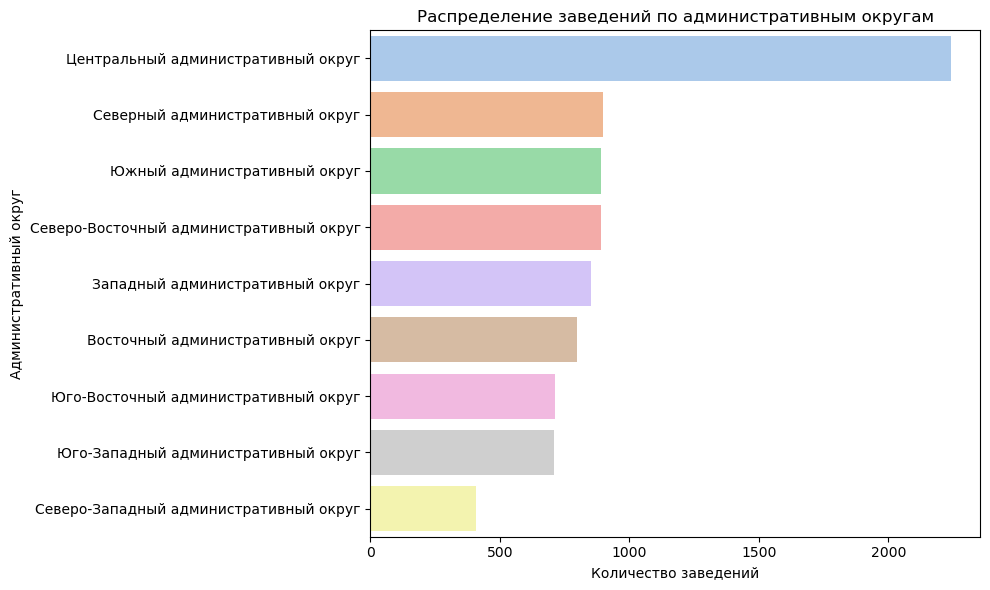


Распределение категорий в ЦАО:
category
ресторан           670
кафе               464
кофейня            428
бар,паб            364
пиццерия           113
быстрое питание     87
столовая            66
булочная            50
Name: count, dtype: int64


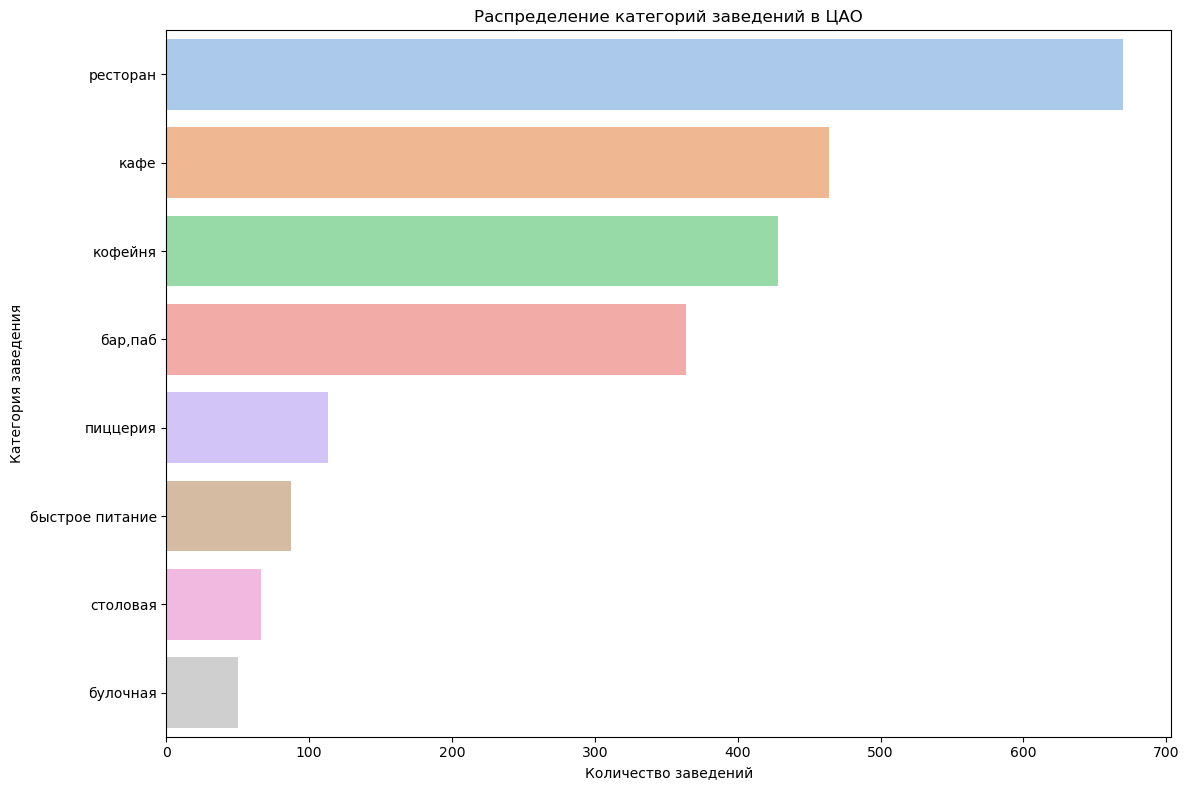


Статистика по районам:
Всего административных округов: 9
Самый популярный округ: Центральный административный округ (всего 2242 заведений)
Самый редкий округ: Северо-Западный административный округ (всего 409 заведений)


In [20]:
# Анализ административных районов
district_counts = df['district'].value_counts()

print("Административные районы Москвы в данных:")
print(district_counts)

# Визуализация распределения по районам
plt.figure(figsize=(10, 6))
sns.barplot(x=district_counts.values, y=district_counts.index, hue=district_counts.index, palette='pastel', legend=False)
plt.title('Распределение заведений по административным округам')
plt.xlabel('Количество заведений')
plt.ylabel('Административный округ')
plt.tight_layout()
plt.show()

# Анализ Центрального административного округа
cao_df = df[df['district'] == 'Центральный административный округ']

cao_category_counts = cao_df['category'].value_counts()

print("\nРаспределение категорий в ЦАО:")
print(cao_category_counts)

# Визуализация
plt.figure(figsize=(12, 8))
sns.barplot(x=cao_category_counts.values, y=cao_category_counts.index, hue=cao_category_counts.index, palette='pastel', legend=False)
plt.title('Распределение категорий заведений в ЦАО')
plt.xlabel('Количество заведений')
plt.ylabel('Категория заведения')
plt.tight_layout()
plt.show()

# Статистика по районам
print("\nСтатистика по районам:")
print(f"Всего административных округов: {len(district_counts)}")
print(f"Самый популярный округ: {district_counts.idxmax()} (всего {district_counts.max()} заведений)")
print(f"Самый редкий округ: {district_counts.idxmin()} (всего {district_counts.min()} заведений)")



_Выводы:_
- Самый популярный округ по количеству заведений - Центральный административный округ (всего 2242 заведений)
- Самы непопулярный округ по количеству заведений - Северо-Западный административный округ (всего 409 заведений)
- Самыми популярными заведениями в ЦАО являются ресторан (670 заведений) и кафе (464)
- Самыми непопулярным заведениями в ЦАО является булочная(50 заведений)

---

### Задача 3

Изучите соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения. Каких заведений больше — сетевых или несетевых? Какие категории заведений чаще являются сетевыми? Исследуйте данные, ответьте на вопросы и постройте необходимые визуализации.

Общее количество сетевых заведений: 3205
Общее количество несетевых заведений: 5201
Доля сетевых заведений: 38.13%


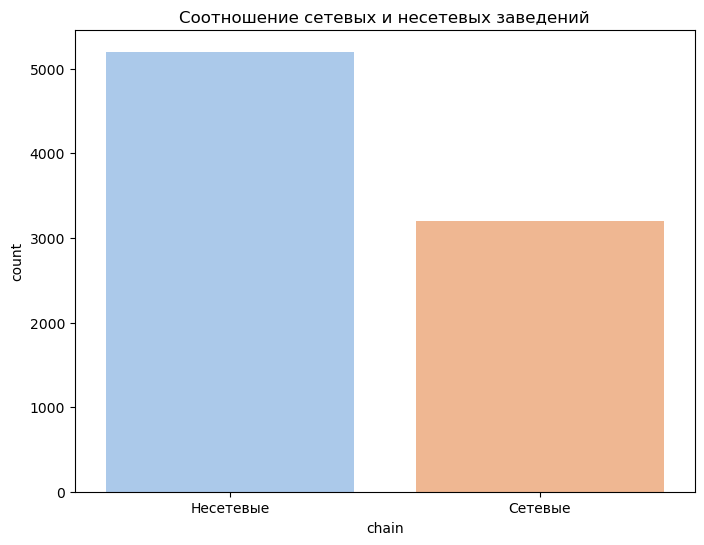


Распределение по категориям:
chain               0    1  total  chain_ratio
category                                      
бар,паб           596  169    765     0.220915
булочная           99  157    256     0.613281
быстрое питание   371  232    603     0.384743
кафе             1599  779   2378     0.327586
кофейня           693  720   1413     0.509554
пиццерия          303  330    633     0.521327
ресторан         1313  730   2043     0.357318
столовая          227   88    315     0.279365


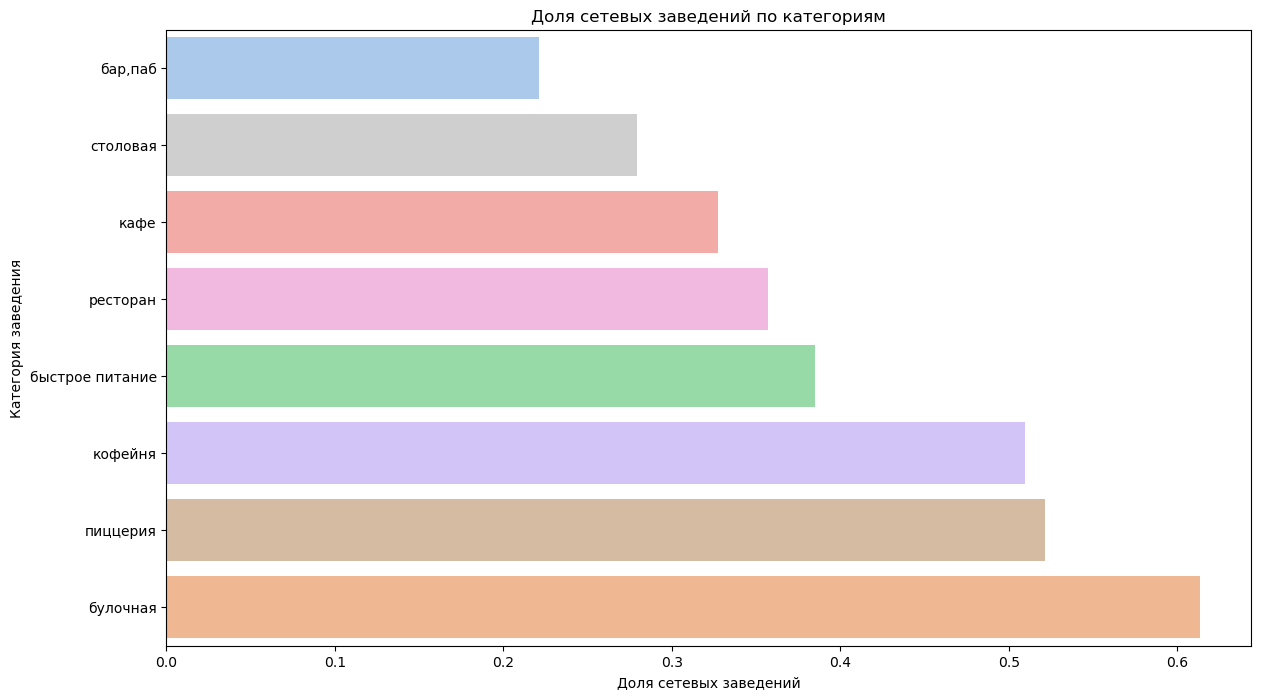


Категории с наибольшей долей сетевых заведений:
chain            chain_ratio
category                    
булочная            0.613281
пиццерия            0.521327
кофейня             0.509554
быстрое питание     0.384743
ресторан            0.357318

Основные выводы:
Всего категорий: 8
Самая сетевая категория: булочная
Минимальная доля сетевых заведений в категории: бар,паб

Статистика по сетевым заведениям:
Среднее количество сетевых заведений на категорию: 400.62
Медианное количество сетевых заведений: 281.0


In [21]:
# Анализ общего соотношения сетевых и несетевых заведений
total_chain = df[df['chain'] == 1].shape[0]
total_non_chain = df[df['chain'] == 0].shape[0]

print(f"Общее количество сетевых заведений: {total_chain}")
print(f"Общее количество несетевых заведений: {total_non_chain}")
print(f"Доля сетевых заведений: {total_chain/(total_chain+total_non_chain):.2%}")

# Визуализация общего соотношения
plt.figure(figsize=(8, 6))
sns.countplot(x='chain', data=df, order=[0, 1], hue = 'chain', palette='pastel', legend = False)
plt.title('Соотношение сетевых и несетевых заведений')
plt.xticks([0, 1], ['Несетевые', 'Сетевые'])
plt.show()

# Анализ по категориям
category_chain = df.groupby(['category', 'chain']).size().unstack(fill_value=0)
category_chain['total'] = category_chain.sum(axis=1)
category_chain['chain_ratio'] = category_chain[1] / category_chain['total']

print("\nРаспределение по категориям:")
print(category_chain)

# Визуализация по категориям
plt.figure(figsize=(14, 8))
sns.barplot(x='chain_ratio', y='category', hue = 'category', legend=False, data=category_chain.reset_index(), 
            palette='pastel', order=category_chain.sort_values('chain_ratio').index)
plt.title('Доля сетевых заведений по категориям')
plt.xlabel('Доля сетевых заведений')
plt.ylabel('Категория заведения')
plt.show()

# Топ категорий по доле сетевых заведений
top_chain_categories = category_chain.sort_values('chain_ratio', ascending=False)
print("\nКатегории с наибольшей долей сетевых заведений:")
print(top_chain_categories[['chain_ratio']].head())

# Статистика
print("\nОсновные выводы:")
print(f"Всего категорий: {len(category_chain)}")
print(f"Самая сетевая категория: {top_chain_categories.index[0]}")
print(f"Минимальная доля сетевых заведений в категории: {top_chain_categories.iloc[-1].name}")

# Дополнительные метрики
print("\nСтатистика по сетевым заведениям:")
print(f"Среднее количество сетевых заведений на категорию: {category_chain[1].mean():.2f}")
print(f"Медианное количество сетевых заведений: {category_chain[1].median()}")


_Основные выводы:_  
- Всего категорий: 8
- Самая сетевая категория: булочная
- Минимальная доля сетевых заведений в категории: бар,паб

_Статистика по сетевым заведениям:_  
- Среднее количество сетевых заведений на категорию: 400.62
- Медианное количество сетевых заведений: 281.0

---

### Задача 4

Исследуйте количество посадочных мест в заведениях. Встречаются ли в данных аномальные значения или выбросы? Если да, то с чем они могут быть связаны? Приведите для каждой категории заведений наиболее типичное для него количество посадочных мест. Результат сопроводите подходящими визуализациями.


Статистика по посадочным местам:
count    4795.000000
mean      108.421689
std       122.833396
min         0.000000
25%        40.000000
50%        75.000000
75%       140.000000
max      1288.000000
Name: seats, dtype: float64


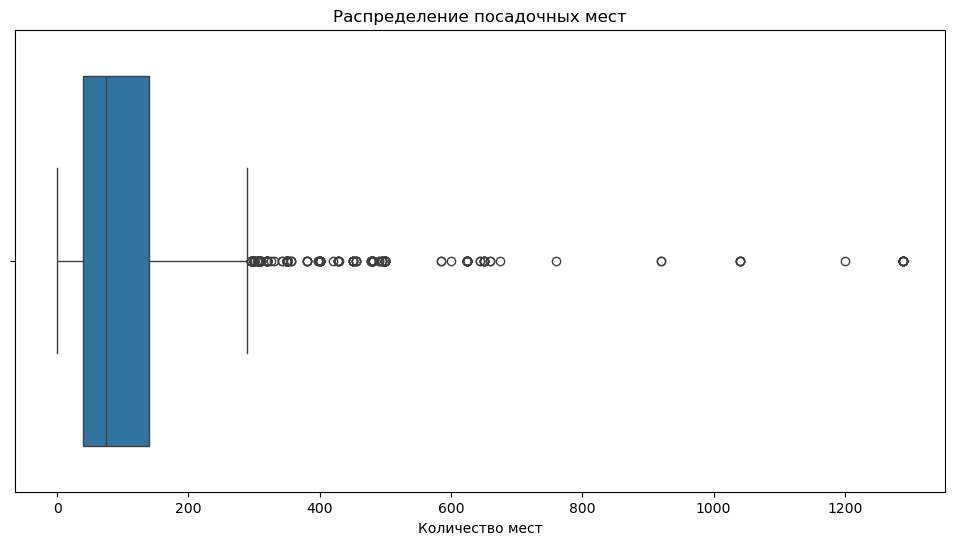


Аномальные значения (отрицательные или нулевые):
seats
0.0    136
Name: count, dtype: int64

Статистика по категориям:
                 median        mean  min     max  count
category                                               
бар,паб            82.5  124.532051  0.0  1288.0    468
булочная           50.0   89.385135  0.0   625.0    148
быстрое питание    65.0   98.891117  0.0  1040.0    349
кафе               60.0   97.512315  0.0  1288.0   1218
кофейня            80.0  111.199734  0.0  1288.0    751
пиццерия           55.0   94.496487  0.0  1288.0    427
ресторан           86.0  121.944094  0.0  1288.0   1270
столовая           75.5   99.750000  0.0  1200.0    164


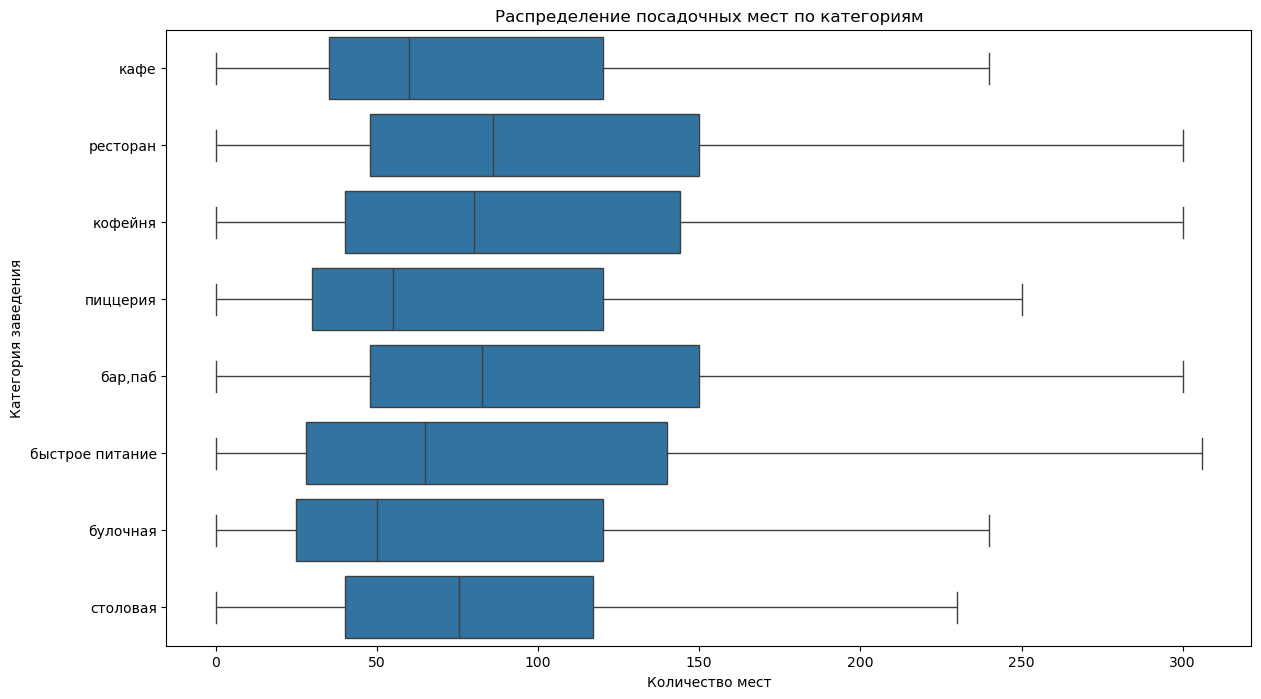


Основные выводы:
Минимальное количество мест: 0.0
Максимальное количество мест: 1288.0
Медианное количество мест: 75.0


In [22]:
# Анализ выбросов
print("Статистика по посадочным местам:")
print(df['seats'].describe())

# Визуализация общего распределения
plt.figure(figsize=(12, 6))
sns.boxplot(x=df['seats'], showfliers=True)
plt.title('Распределение посадочных мест')
plt.xlabel('Количество мест')
plt.show()

# Анализ аномальных значений
print("\nАномальные значения (отрицательные или нулевые):")
print(df[df['seats'] <= 0]['seats'].value_counts())

# Группировка по категориям
seats_by_category = df.groupby('category')['seats'].agg(['median', 'mean', 'min', 'max', 'count'])
print("\nСтатистика по категориям:")
print(seats_by_category)

# Визуализация по категориям
plt.figure(figsize=(14, 8))
sns.boxplot(x='seats', y='category', data=df, showfliers=False)
plt.title('Распределение посадочных мест по категориям')
plt.xlabel('Количество мест')
plt.ylabel('Категория заведения')
plt.show()


# Вывод результатов
print("\nОсновные выводы:")
print(f"Минимальное количество мест: {df['seats'].min()}")
print(f"Максимальное количество мест: {df['seats'].max()}")
print(f"Медианное количество мест: {df['seats'].median()}")


_Выводы_  
Распределение посадочных мест:  
Аномальные значения есть: кол-во нулевых посадочных мест - 136. Скорее всего это связано с некорректностью заполнения сведений о местах владельцами заведений  
- Основное распределение от 4 до 250 мест
- Медиана около 50


---

### Задача 5

Исследуйте рейтинг заведений. Визуализируйте распределение средних рейтингов по категориям заведений. Сильно ли различаются усреднённые рейтинги для разных типов общепита?

Общая статистика рейтингов:
count    8406.000000
mean        4.229895
std         0.470348
min         1.000000
25%         4.100000
50%         4.300000
75%         4.400000
max         5.000000
Name: rating, dtype: float64

Статистика рейтингов по категориям:
                     mean  median  min  max  count
category                                          
бар,паб          4.387712     4.4  1.1  5.0    765
булочная         4.268359     4.3  1.3  5.0    256
быстрое питание  4.050249     4.2  1.1  5.0    603
кафе             4.123886     4.2  1.0  5.0   2378
кофейня          4.277282     4.3  1.4  5.0   1413
пиццерия         4.301264     4.3  1.0  5.0    633
ресторан         4.290357     4.3  1.0  5.0   2043
столовая         4.211429     4.3  1.0  5.0    315


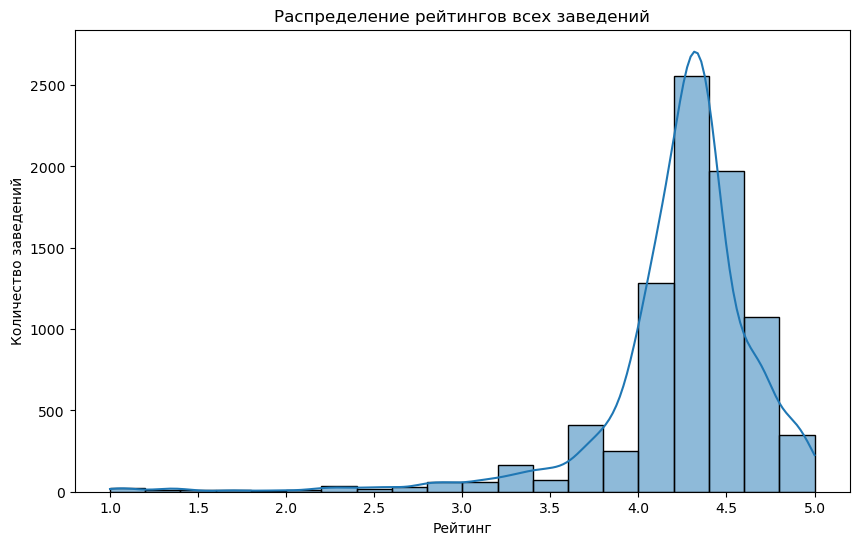

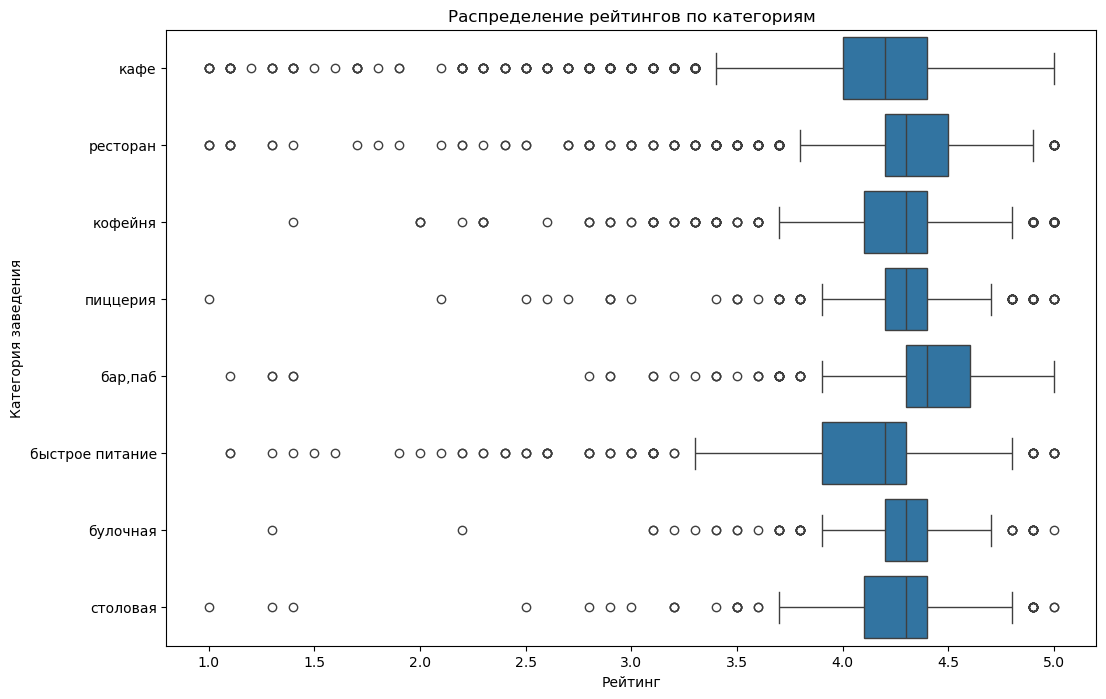

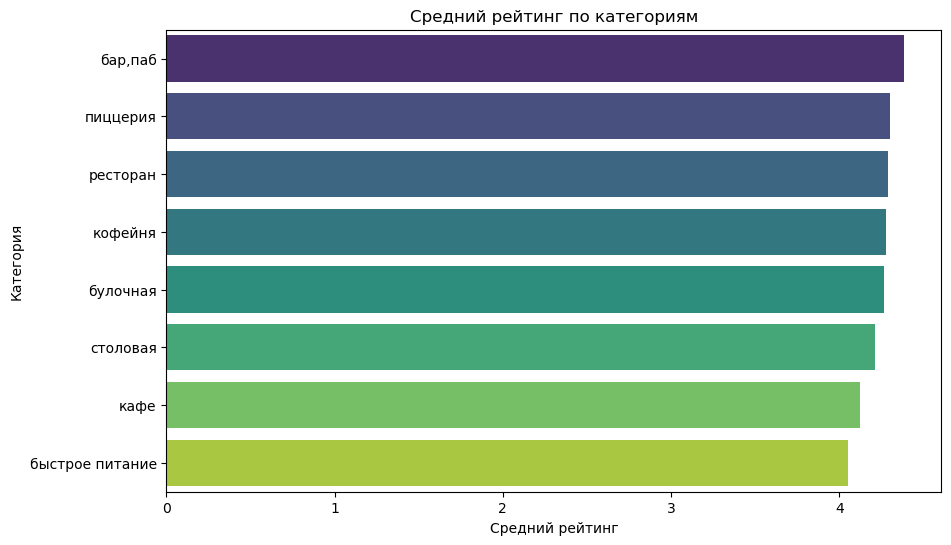


Основные выводы:
Средний рейтинг по всем заведениям: 4.23
Медианный рейтинг: 4.30

Категории с наивысшими средними рейтингами:
category
бар,паб     4.387712
пиццерия    4.301264
ресторан    4.290357
кофейня     4.277282
булочная    4.268359
Name: rating, dtype: float64

Категории с наименьшими средними рейтингами:
category
кофейня            4.277282
булочная           4.268359
столовая           4.211429
кафе               4.123886
быстрое питание    4.050249
Name: rating, dtype: float64


In [23]:
# Базовый анализ рейтингов
print("Общая статистика рейтингов:")
print(df['rating'].describe())

# Анализ по категориям
category_rating = df.groupby('category')['rating'].agg(['mean', 'median', 'min', 'max', 'count'])
print("\nСтатистика рейтингов по категориям:")
print(category_rating)

# Визуализация общего распределения
plt.figure(figsize=(10, 6))
sns.histplot(df['rating'], bins=20, kde=True)
plt.title('Распределение рейтингов всех заведений')
plt.xlabel('Рейтинг')
plt.ylabel('Количество заведений')
plt.show()

# Визуализация по категориям
plt.figure(figsize=(12, 8))
sns.boxplot(x='rating', y='category', data=df, showfliers=True)
plt.title('Распределение рейтингов по категориям')
plt.xlabel('Рейтинг')
plt.ylabel('Категория заведения')
plt.show()

# Сравнение средних рейтингов
avg_ratings = df.groupby('category')['rating'].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=avg_ratings.values, y=avg_ratings.index, hue=avg_ratings.index, palette='viridis')
plt.title('Средний рейтинг по категориям')
plt.xlabel('Средний рейтинг')
plt.ylabel('Категория')
plt.show()


# Вывод результатов
print("\nОсновные выводы:")
print(f"Средний рейтинг по всем заведениям: {df['rating'].mean():.2f}")
print(f"Медианный рейтинг: {df['rating'].median():.2f}")
print("\nКатегории с наивысшими средними рейтингами:")
print(avg_ratings.head())
print("\nКатегории с наименьшими средними рейтингами:")
print(avg_ratings.tail())



_Вывод_  
Видно, что медианные и средние значения рейтинги заведений близки друг к другу и близки к рейтингу 4.3.  
Категории с наивысшими средними рейтингами: 
- бар,паб     4.387712
- пиццерия    4.301264
- ресторан    4.290357
- кофейня     4.277282
- булочная    4.268359

Категории с наименьшими средними рейтингами:  
- кофейня            4.277282
- булочная           4.268359
- столовая           4.211429
- кафе               4.123886
- быстрое питание    4.050249

---

### Задача 6

Изучите, с какими данными показывают самую сильную корреляцию рейтинги заведений? Постройте и визуализируйте матрицу корреляции рейтинга заведения с разными данными: его категория, положение (административный район Москвы), статус сетевого заведения, количество мест, ценовая категория и признак, является ли заведения круглосуточным. Выберите самую сильную связь и проверьте её.

interval columns not set, guessing: ['rating', 'seats', 'middle_avg_bill']


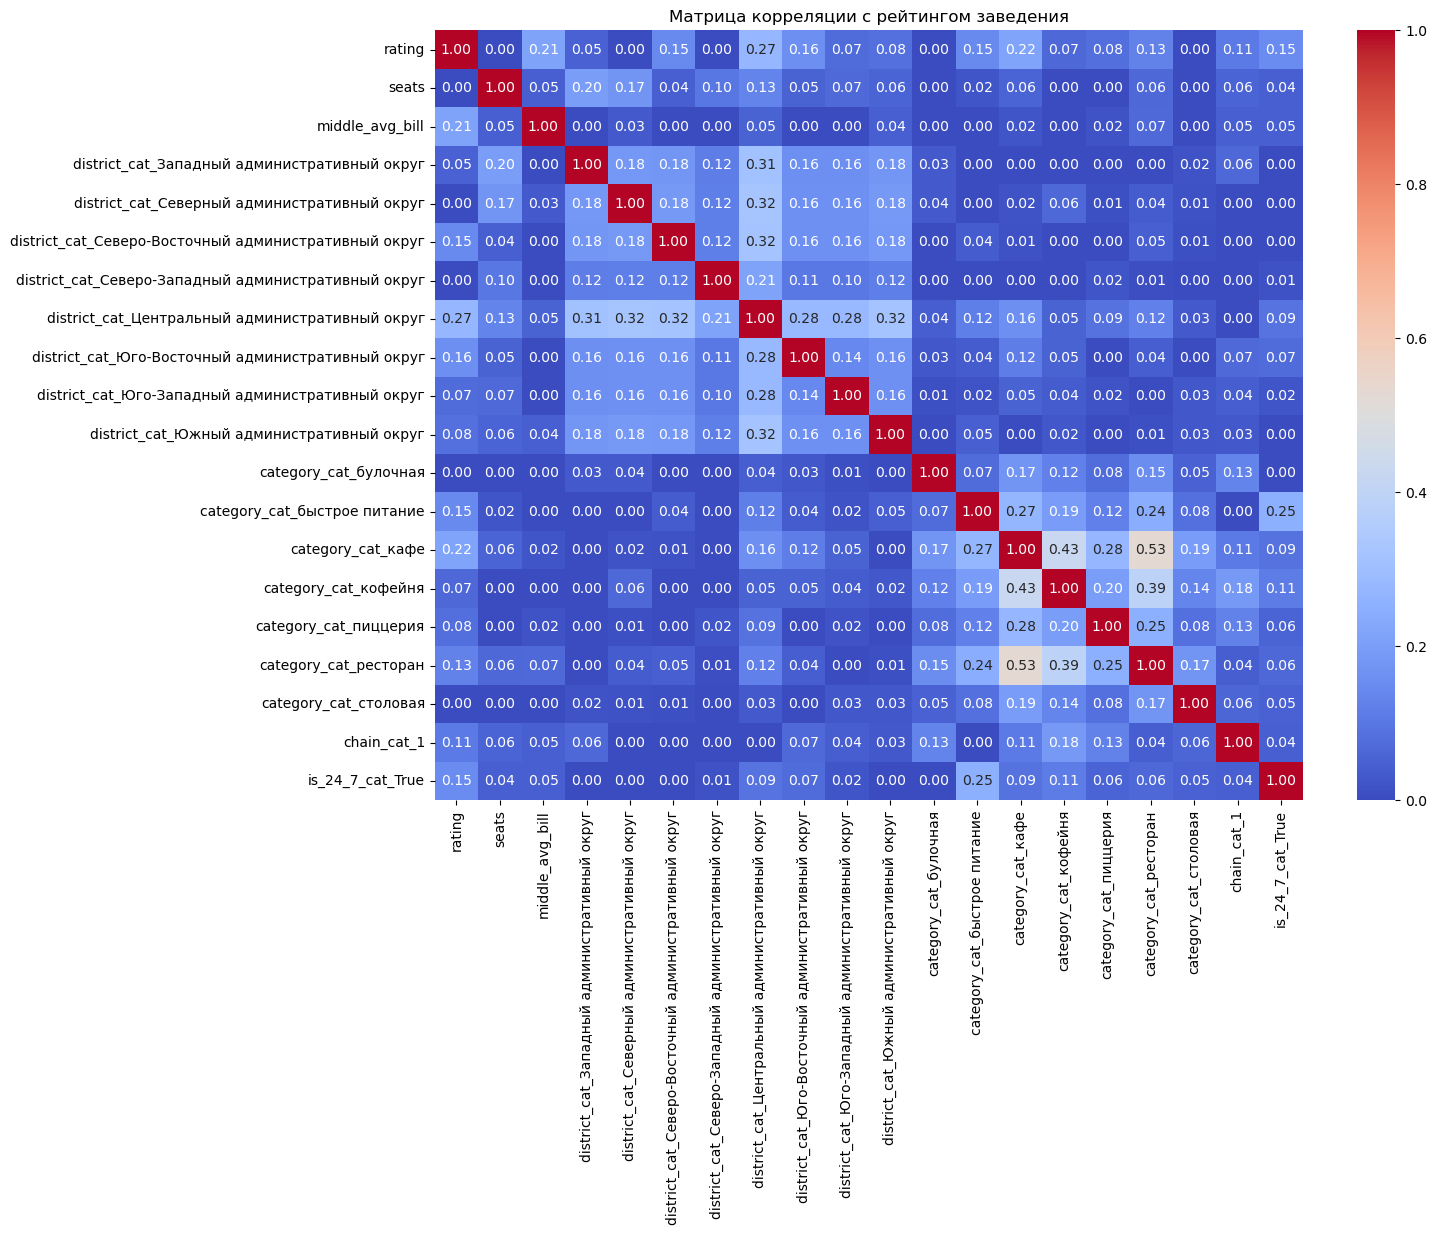

Самые сильные корреляции с рейтингом:
rating                                                  1.000000
district_cat_Центральный административный округ         0.274167
category_cat_кафе                                       0.216511
middle_avg_bill                                         0.211868
district_cat_Юго-Восточный административный округ       0.157581
is_24_7_cat_True                                        0.150173
category_cat_быстрое питание                            0.146138
district_cat_Северо-Восточный административный округ    0.146074
category_cat_ресторан                                   0.126464
chain_cat_1                                             0.108092
district_cat_Южный административный округ               0.082068
category_cat_пиццерия                                   0.081602
district_cat_Юго-Западный административный округ        0.073957
category_cat_кофейня                                    0.066083
district_cat_Западный административный округ        

In [24]:
# Создаем категориальные переменные для анализа
df['district_cat'] = df['district'].astype('category')
df['category_cat'] = df['category'].astype('category')
df['chain_cat'] = df['chain'].astype('category')
df['is_24_7_cat'] = df['is_24_7'].astype('category')

# Подготавливаем данные для корреляционного анализа
corr_df = df[['rating', 'seats', 'middle_avg_bill', 
             'district_cat', 'category_cat', 'chain_cat', 'is_24_7_cat']]

# Заменяем категориальные переменные на dummy-переменные
corr_df = pd.get_dummies(corr_df, drop_first=True)

# Вычисляем корреляцию
corr_matrix = corr_df.phik_matrix()

# Визуализация матрицы корреляции
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Матрица корреляции с рейтингом заведения')
plt.show()

# Находим самую сильную корреляцию
max_corr = corr_matrix['rating'].abs().sort_values(ascending=False)
print("Самые сильные корреляции с рейтингом:")
print(max_corr)


# Вывод результатов
print("\nОсновные выводы:")
print(f"Самая сильная корреляция с рейтингом: {max_corr.index[1]}")
print(f"Коэффициент корреляции: {max_corr.iloc[1]:.2f}")


_Выводы_  
Самая сильная корреляция с рейтингом: Центральный административный округ
Коэффициент корреляции: 0.27

---

### Задача 7

Сгруппируйте данные по названиям заведений и найдите топ-15 популярных сетей в Москве. Для них посчитайте значения среднего рейтинга. Под популярностью понимается количество заведений этой сети в регионе. К какой категории заведений они относятся? Результат сопроводите подходящими визуализациями.

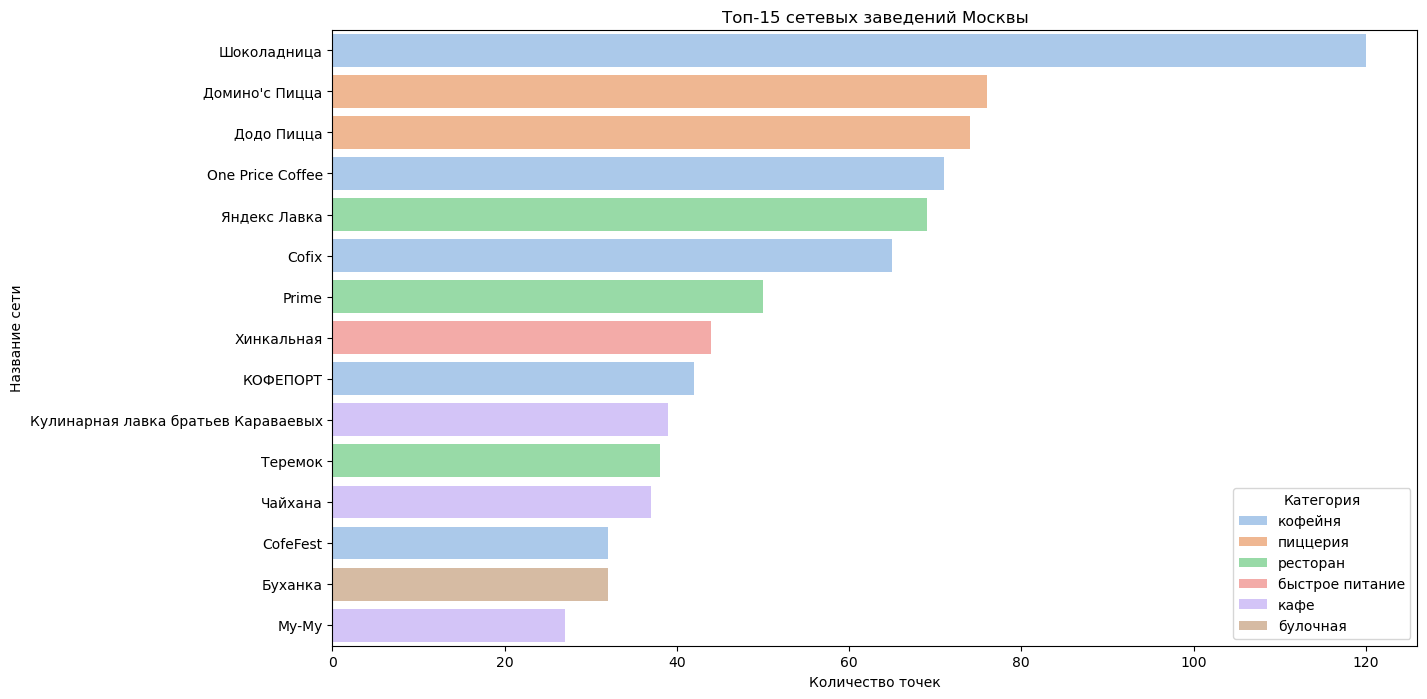

Топ-15 сетевых заведений:
                                     name  count         category  avg_rating
5522                          Шоколадница    120          кофейня    4.177500
2584                       Домино'с Пицца     76         пиццерия    4.169737
2551                           Додо Пицца     74         пиццерия    4.286486
1156                     One Price Coffee     71          кофейня    4.064789
5595                         Яндекс Лавка     69         ресторан    3.872464
419                                 Cofix     65          кофейня    4.075385
1290                                Prime     50         ресторан    4.116000
5083                           Хинкальная     44  быстрое питание    4.322727
2825                             КОФЕПОРТ     42          кофейня    4.147619
3302  Кулинарная лавка братьев Караваевых     39             кафе    4.394872
4788                              Теремок     38         ресторан    4.123684
5208                              Чайх

In [25]:
# Группируем по названию и считаем количество точек
network_counts = df.groupby('name').agg(
    count=('name', 'size'),
    avg_rating=('rating', 'mean'),
    category=('category', 'first'),
    is_chain=('chain', 'first')
).reset_index()

# Отбираем только сетевые заведения
network_counts = network_counts[network_counts['is_chain'] == 1]

# Выбираем топ-15 сетей
top_networks = network_counts.sort_values(by='count', ascending=False).head(15)

# Визуализация
plt.figure(figsize=(14, 8))
sns.barplot(
    x='count', 
    y='name', 
    hue='category', 
    data=top_networks,
    palette='pastel'
)
plt.title('Топ-15 сетевых заведений Москвы')
plt.xlabel('Количество точек')
plt.ylabel('Название сети')
plt.legend(title='Категория')
plt.show()

# Вывод детальной информации
print("Топ-15 сетевых заведений:")
print(top_networks[['name', 'count', 'category', 'avg_rating']].sort_values('count', ascending=False))



_Вывод_  
_Самое популярное заведение - `Шоколодница` по количеству заведений (120 шт), у неё же самый высокий средний рейтинг (4.17), что логично.  
Данной заведение относится к категории `кофейня`_

---

### Задача 8

Изучите вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы. Проанализируйте цены в Центральном административном округе и других. Как удалённость от центра влияет на цены в заведениях? Результат сопроводите подходящими визуализациями.


Средние цены по районам:
                                                mean  median          std
district                                                                 
Центральный административный округ       1191.057547  1000.0   920.014707
Западный административный округ          1053.225490  1000.0   779.008536
Северный административный округ           927.959627   650.0   912.609221
Южный административный округ              834.398089   500.0  2008.640596
Северо-Западный административный округ    822.222930   700.0   595.055218
Восточный административный округ          820.626923   575.0   850.903310
Юго-Западный административный округ       792.561702   600.0   559.173122
Северо-Восточный административный округ   716.611296   500.0   591.232153
Юго-Восточный административный округ      654.097938   450.0   566.825663


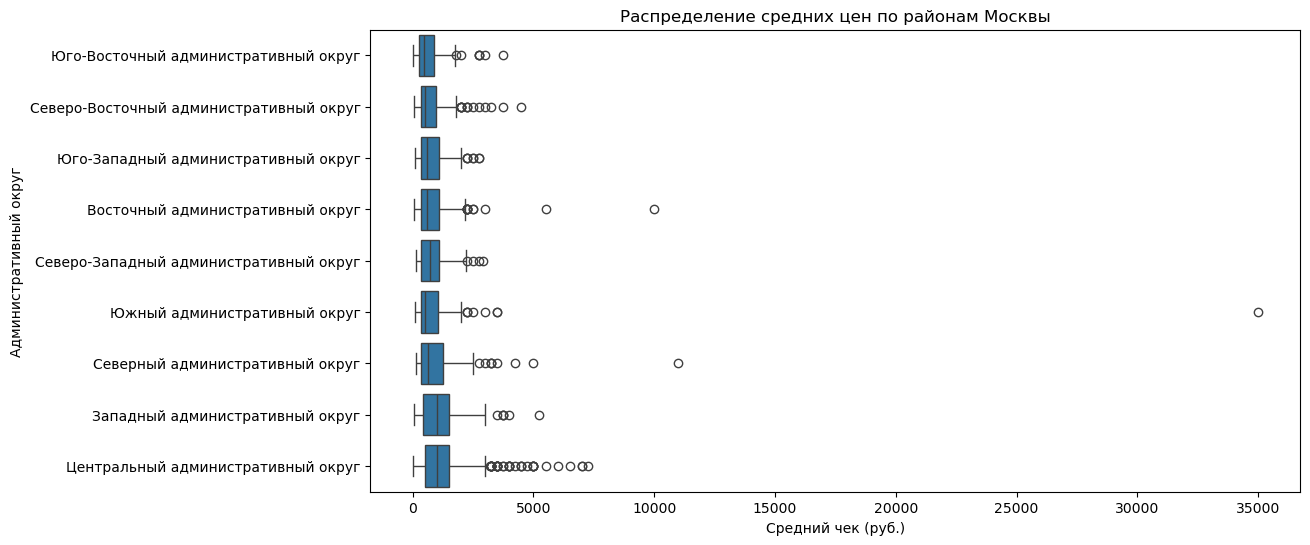

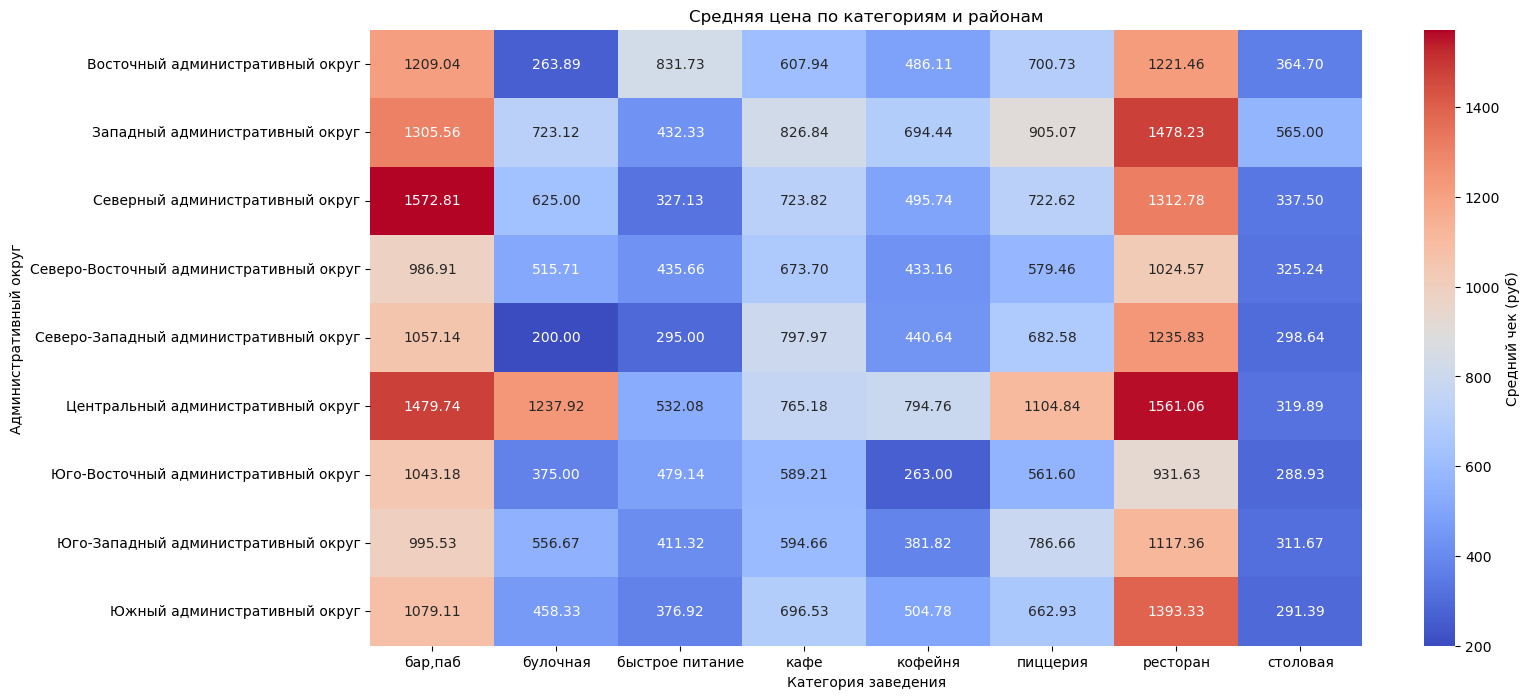

In [26]:
# Очищаем данные от пропусков в среднем чеке
df_clean = df.dropna(subset=['middle_avg_bill'])

# Анализ средних цен по районам
district_avg_price = df_clean.groupby('district')['middle_avg_bill'].agg(['mean', 'median', 'std'])
print("Средние цены по районам:")
print(district_avg_price.sort_values(by='mean', ascending=False))

# Визуализация распределения цен по районам
plt.figure(figsize=(12, 6))
sns.boxplot(x='middle_avg_bill', y='district', data=df_clean, 
            order=district_avg_price.sort_values('mean').index)
plt.title('Распределение средних цен по районам Москвы')
plt.xlabel('Средний чек (руб.)')
plt.ylabel('Административный округ')
plt.show()

# Анализ цен в разрезе категорий и районов
category_district_price = df_clean.groupby(['district', 'category'])['middle_avg_bill'].mean().unstack()

# Визуализация
plt.figure(figsize=(16, 8))
sns.heatmap(category_district_price, annot=True, fmt='.2f', cmap='coolwarm', 
            cbar_kws={'label': 'Средний чек (руб)'})
plt.title('Средняя цена по категориям и районам')
plt.xlabel('Категория заведения')
plt.ylabel('Административный округ')
plt.show()


_Выводы:_ 
- Самые высокие средние цены наблюдаются в Центральном административном округе - 1191 руб. Что не удивительно, поскольку в нем и самое большее количество заведений. В разрезе категорий на тепловой карте также видно, что в центральном округе фиксируется самый высокий средний чек.

### _Промежуточный вывод_  

На основе проведенных исследование можно сделать следующие выводы:  
- Самой популярной категорией заведения является - "кафе"
- В статистике предсавлены 9 административных округов, самый популярный округ по количеству заведений: Центральный административный округ (всего 2242 заведений)
- При исследовании сетевых заведений, было выявлено, что самая сетевая категория: булочная
- При исследовании посадочных мест, основное распределение от 4 до 250 мест
- При иссследовании рейтингов заведений, было установлено, что Средний рейтинг по всем заведениям: 4.23
Медианный рейтинг: 4.30
- Самая сильная корреляция с рейтингом у Центрального административного округа. Коэффициент корреляции: 0.27
- Были выявлены топ-15 популярных сетей в Москве. Самая популярная сеть по значению среднего рейтинга - `шоколадница`
- Самые высокие средние цены наблюдаются в Центральном административном округе - 1191 руб. 

## 4. Итоговый вывод и рекомендации

1. Были исследованы два исходных датасета, которые были объединены в один. Он был предобработан и над ним проведены 8 исследований.
2. Выводы по исследованиям представлены в промежуточных выводах проекта и абзацем выше
3. На основе проведенных исследований, Заказчику рекомендовано присмотреться к открытию сетевого заведения с категорией кафе в Центральном административном округе со средним медианным числом посадочных мест 75.